In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, GlobalAveragePooling2D,
    Dense, Dropout
)
from tensorflow.keras.utils import to_categorical

In [3]:
# Set dataset path and select categories

In [4]:
DATASET_PATH = r"C:\Users\Dell\Downloads\caltech-101\caltech-101\101_ObjectCategories\101_ObjectCategories"

categories = [
    "cougar_body",
    "yin_yang",
    "windsor_chair",
    "wrench",
    "wheelchair"
]

IMG_SIZE = 224

In [5]:
# Load and preprocess images

In [6]:
images = []
labels = []

extensions = [".jpg", ".jpeg", ".png", ".bmp"]

for label, category in enumerate(categories):

    folder = Path(DATASET_PATH) / category

    image_files = [
        file for file in folder.rglob("*")
        if file.suffix.lower() in extensions
    ][:100]

    print(category, ":", len(image_files))

    for file in image_files:

        img = tf.keras.utils.load_img(
            file,
            target_size=(224, 224)
        )

        img = tf.keras.utils.img_to_array(img)

        images.append(img)
        labels.append(label)

X = np.array(images, dtype=np.float32)
y = np.array(labels)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)

cougar_body : 47
yin_yang : 60
windsor_chair : 56
wrench : 39
wheelchair : 59
Images shape: (261, 224, 224, 3)
Labels shape: (261,)


In [7]:
# Split training and testing data

In [8]:
X_train, X_test, y_train, y_test, X_train_original, X_test_original = train_test_split(
    X, y, X,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [9]:
# Convert labels into categorical format

In [10]:
y_train = to_categorical(y_train, num_classes=5)
y_test = to_categorical(y_test, num_classes=5)

In [11]:
# Preprocess images for VGG16

In [12]:
X_train = preprocess_input(X_train)
X_test = preprocess_input(X_test)

In [13]:
# Load pretrained VGG16 model

In [14]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

In [15]:
# Add custom classification head

In [16]:
inputs = Input(shape=(224, 224, 3))

x = base_model(inputs)

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation="relu")(x)

x = Dense(128, activation="relu")(x)

x = Dropout(0.5)(x)

outputs = Dense(5, activation="softmax")(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,879,557 (56.76 MB)

 Trainable params: 164,869 (644.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [17]:
# Compile the model

In [18]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
# Train the model

In [20]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=16,
    validation_split=0.2
)

Epoch 1/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 78s 7s/step - accuracy: 0.5663 - loss: 3.7083 - val_accuracy: 0.9286 - val_loss: 0.1944
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 68s 6s/step - accuracy: 0.8735 - loss: 0.3137 - val_accuracy: 0.9286 - val_loss: 0.1414
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 70s 6s/step - accuracy: 0.9699 - loss: 0.0512 - val_accuracy: 1.0000 - val_loss: 0.0217
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 69s 6s/step - accuracy: 0.9880 - loss: 0.0534 - val_accuracy: 1.0000 - val_loss: 0.0164
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.9880 - loss: 0.0207 - val_accuracy: 1.0000 - val_loss: 0.0166
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.9880 - loss: 0.0393 - val_accuracy: 0.9762 - val_loss: 0.0644
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.9880 - loss: 0.0265 - val_accuracy: 0.9762 - val_loss: 0.0802
Epoch 10/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.9819 - loss: 0.0356 - val_accuracy: 1.0000 - val_loss

In [21]:
# Display training and validation accuracy

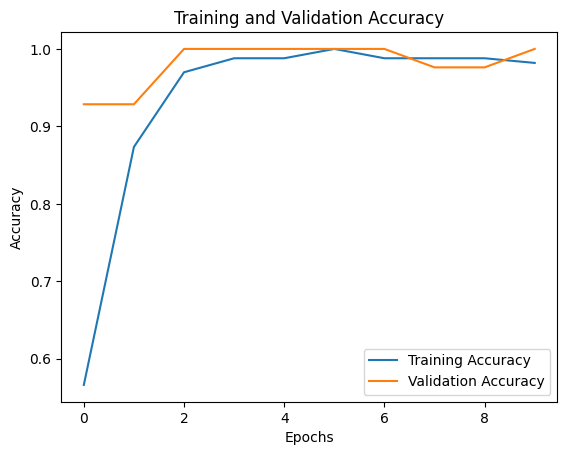

In [22]:
plt.plot(history.history["accuracy"], label="Training Accuracy")

plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.show()

In [23]:
# Evaluate model on test data

In [24]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Testing Accuracy:", accuracy * 100, "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 8s 3s/step - accuracy: 0.9811 - loss: 0.0586
Testing Accuracy: 98.11320900917053 %


In [25]:
# Predict object categories for five test images

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 736ms/step
Predicted: cougar_body
Actual: cougar_body
----------------------
Predicted: windsor_chair
Actual: windsor_chair
----------------------
Predicted: cougar_body
Actual: cougar_body
----------------------
Predicted: windsor_chair
Actual: windsor_chair
----------------------
Predicted: cougar_body
Actual: cougar_body
----------------------


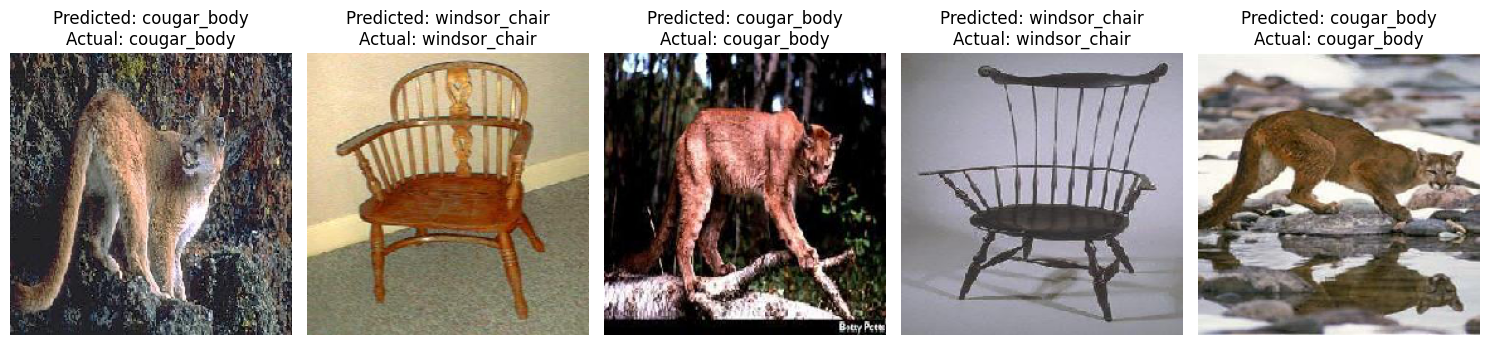

In [27]:
# Predict five test images
predictions = model.predict(X_test[:5])

predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test[:5], axis=1)

# Display images with predictions
plt.figure(figsize=(15, 8))

for i in range(5):

    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test_original[i].astype("uint8"))

    predicted = categories[predicted_labels[i]]
    actual = categories[actual_labels[i]]

    plt.title(f"Predicted: {predicted}\nActual: {actual}")

    plt.axis("off")

    print("Predicted:", predicted)
    print("Actual:", actual)
    print("----------------------")

plt.tight_layout()
plt.show()